# The Kansas income-tax cuts

Quarterly log GDP per capita, 1990 Q1–2016 Q1; treatment starts 2012.25 as in the authors' vignette. Outcome: natural log GDP per capita.

Ben-Michael, Feller and Rothstein (2021), [JASA](https://doi.org/10.1080/01621459.2021.1929245). Reproduce the no-covariate Ridge ASCM example from the authors' [augsynth vignette](https://github.com/ebenmichael/augsynth/blob/master/vignettes/singlesynth-vignette.md): ATT −0.0401, tolerance 0.001. The exact percent change corresponding to a log gap is `100 * expm1(gap)`. The 2012.25 onset follows the reference data and should not be interpreted as a fresh legislative-timing claim.

Run from a checkout installed using `requirements-replication.txt` and `pip install -e .`. This notebook downloads immutable public data using **requests**; an internet connection is required. See [the replication guide](../docs/replication.md) for provenance and scope.

In [1]:
%matplotlib inline
import hashlib
from io import BytesIO
from importlib.metadata import version

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

from pysynth import (SyntheticControl, SCUL, IndividualSC, TwoStageIndividualSC, SyntheticDID,
                     DifferenceInDifferences, PySyncon, SCM, compare)
from pysynth.datasets import DATASETS
from pysynth.replication import replicate, check_replication

pd.Series({p: version(p) for p in ['pysynth-control', 'numpy', 'scipy', 'pandas', 'pysyncon', 'SyntheticControlMethods']}, name='version')

pysynth-control             0.1.0
numpy                       2.0.2
scipy                      1.13.1
pandas                      2.3.3
pysyncon                    1.7.0
SyntheticControlMethods    1.1.17
Name: version, dtype: object

## Download and verify the academic data

The URL names an immutable upstream commit. SHA256 verification fails visibly if the bytes differ. No manual download or bundled dataset is required.

In [2]:
name = 'kansas'
spec = DATASETS[name]
response = requests.get(spec.url, timeout=30)
response.raise_for_status()
assert hashlib.sha256(response.content).hexdigest() == spec.sha256
data = pd.read_csv(BytesIO(response.content), sep=spec.separator)
panel = spec.panel(data)
print(spec.citation)
print(spec.url)
print(f'{panel.n_control} donors; {panel.n_pre} pre-periods; {panel.n_post} post-periods')
data.head()

Ben-Michael, Feller & Rothstein (2021), doi:10.1080/01621459.2021.1929245
https://raw.githubusercontent.com/sdfordham/pysyncon/b77dc20e29b012ab03ca1d4caeef7b41861e86f5/data/kansas.csv
49 donors; 89 pre-periods; 16 post-periods


,fips,state,abb,year_qtr,lngdpcapita,treated,revstatecapita,revlocalcapita,avgwklywagecapita,estabscapita,emplvlcapita
0,1.0,Alabama,AL,1990.00,9.780260,0.0,NaN,NaN,382.0,0.021379,0.388961
1,1.0,Alabama,AL,1990.25,9.792591,0.0,NaN,NaN,388.0,0.021216,0.396142
2,1.0,Alabama,AL,1990.50,9.804699,0.0,NaN,NaN,388.0,0.021302,0.393884
3,1.0,Alabama,AL,1990.75,9.816591,0.0,NaN,NaN,416.0,0.021512,0.394967
4,1.0,Alabama,AL,1991.00,9.828273,0.0,NaN,NaN,396.0,0.022352,0.386480


## Reference specification and numerical check

This cell uses the historical specification described above. Its assertion is separate from the new-method comparison. See `pysynth.replication.replicate` for the full predictor windows and optimization settings.

source                R augsynth vignette ATT, log GDP per capita
estimate                                                -0.040063
reference                                                 -0.0401
absolute_tolerance                                          0.001
Name: Replication check, dtype: object

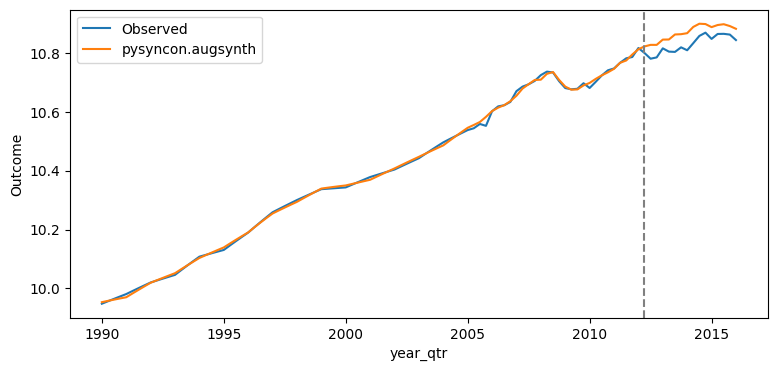

In [3]:
reference = replicate(name, data)
report = check_replication(name, reference)
display(pd.Series(report, name='Replication check'))
reference.plot()
plt.show()

## Compare all applicable methods

All rows use the same outcome panel, donor eligibility and intervention date. Native SCM assigns equal importance to outcome periods; the pysyncon SCM adapter standardizes predictor rows. Penalized and robust SCM use explicit illustrative tuning values below. The SyntheticControlMethods rows use at most ten evenly spaced pre-outcome lag predictors plus its outcome mean; this keeps the nested optimization practical for quarterly panels. SCUL selects its penalty by rolling validation entirely within the pre-period, using a shared pretreatment penalty grid.

Vanilla Individual Synthetic Control (ISC) fits over the full eligible donor pool. Two-Stage Individual Synthetic Control (2SISC) first selects up to ten nearest donors by pretreatment Euclidean distance, then fits convex weights within that group. Both are shown separately. With one aggregate treated case, default outcome features and no resampling, vanilla ISC coincides with Outcome SCM; that agreement is expected. These applications do not reproduce the Vagni–Breen survey study. SDID uses donor post-period outcomes to learn time weights, and robust SCM denoises donors over the full panel; neither uses treated post outcomes to estimate weights. The newer methods' rows are **new applications**, not estimates published in their development papers.

Upstream convergence warnings remain visible. No method is silently dropped if fitting fails.

In [4]:
models = {
    'Outcome SCM': SyntheticControl(),
    'SCUL': SCUL(initial_window=max(3, panel.n_pre // 2), horizon=1),
    'ISC (full donor pool)': IndividualSC(),
    '2SISC (nearest 10)': TwoStageIndividualSC(n_neighbors=10),
    'Synthetic DID': SyntheticDID(),
    'DID': DifferenceInDifferences(),
    'pysyncon SCM': PySyncon('synth'),
    'Augmented SCM': PySyncon('augsynth'),
    'Penalized SCM (0.01)': PySyncon('pensynth', options={'lambda_': 0.01}),
    'Robust SCM (rank 3, ridge 0.1)': PySyncon('robust', options={'lambda_': 0.1, 'sv_count': 3}),
    'SyntheticControlMethods SCM': SCM('synth', n_lags=10),
    'Differenced SCM': SCM('diffsynth', n_lags=10),
}
results = {label: model.fit(panel) for label, model in models.items()}
comparison = compare(results)
comparison.round(4)

/tmp/ipykernel_3587376/4148541051.py:15: RuntimeWarning: SDID reached max_iter before the objective-decrease stopping rule
  results = {label: model.fit(panel) for label, model in models.items()}


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           11     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  1.10821D-02    |proj g|=  8.91735D-03
  ys=-9.653E-06  -gs= 2.380E-04 BFGS update SKIPPED
  ys=-2.212E-03  -gs= 2.045E-03 BFGS update SKIPPED

At iterate    3    f=  8.66754D-03    |proj g|=  1.74703D-02



At iterate    6    f=  7.98912D-03    |proj g|=  5.75730D-03

At iterate    9    f=  7.96583D-03    |proj g|=  1.31832D-03



At iterate   12    f=  7.93675D-03    |proj g|=  1.59752D-03



At iterate   15    f=  7.86597D-03    |proj g|=  6.68564D-03



           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
   11     17     35     17     2     0   4.592D-03   7.857D-03
  F =   7.8572680827016395E-003

CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH             
RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           11     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  5.44725D-03    |proj g|=  9.09091D-02


... (6 outputs left out)

  ys=-8.714E-07  -gs= 4.170E-06 BFGS update SKIPPED



At iterate   18    f=  4.17438D-03    |proj g|=  2.27532D-03
  ys=-2.355E-10  -gs= 2.396E-08 BFGS update SKIPPED



           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
   11     19     71     20     3     0   2.235D-03   4.174D-03
  F =   4.1743810185826437E-003

CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH             


,att,pre_rmse,donors_used,weight_sum
model,,,,
Outcome SCM,-0.0204,0.0090,10,1.0000
SCUL,-0.0450,0.0073,7,0.9002
ISC (full donor pool),-0.0204,0.0090,10,1.0000
2SISC (nearest 10),-0.0053,0.0212,4,1.0000
Synthetic DID,-0.0367,0.0186,23,1.0000
DID,0.0228,0.0194,49,1.0000
pysyncon SCM,-0.0276,0.0088,7,1.0000
Augmented SCM,-0.0401,0.0065,49,1.0000
Penalized SCM (0.01),-0.0322,0.0114,7,1.0000


## Estimated effect paths

Differences across estimates reflect different restrictions, extrapolation, regularization and level adjustments. Pre-period RMSE measures fit; it does not validate the identifying assumptions or rank causal credibility.

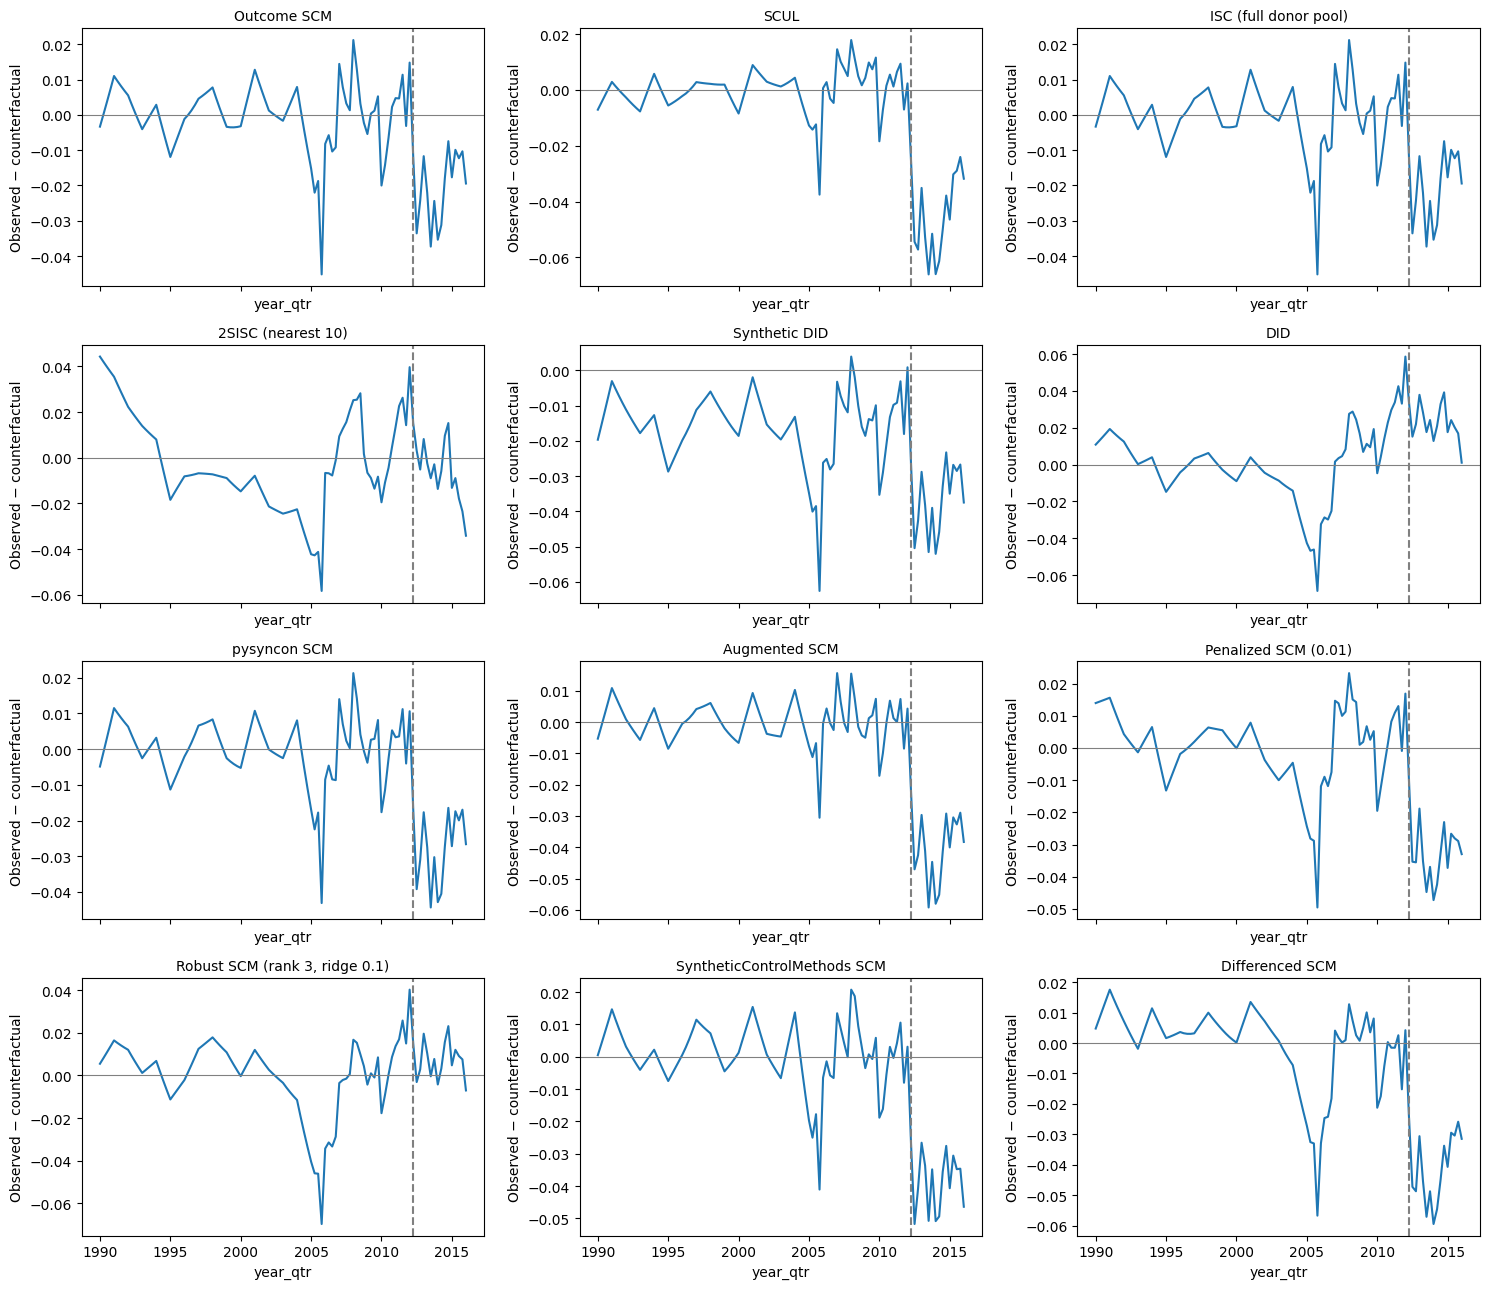

In [5]:
fig, axes = plt.subplots(4, 3, figsize=(15, 13), sharex=True)
for ax, (label, result) in zip(axes.flat, results.items()):
    result.plot(ax=ax, effects=True)
    ax.set_title(label, fontsize=10)
    ax.get_legend().remove()
for ax in list(axes.flat)[len(results):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()

In [6]:
weights = pd.concat({label: fit.weights for label, fit in results.items()}, axis=1)
weights.loc[weights.abs().max(axis=1).sort_values(ascending=False).index].head(15).round(4)

,Outcome SCM,SCUL,ISC (full donor pool),2SISC (nearest 10),Synthetic DID,DID,pysyncon SCM,Augmented SCM,Penalized SCM (0.01),"Robust SCM (rank 3, ridge 0.1)",SyntheticControlMethods SCM,Differenced SCM
42.0,0.0585,0.1937,0.0585,0.3683,0.0616,0.0204,0.0000,0.0074,0.3149,0.0210,0.0000,0.0000
48.0,0.1355,0.3571,0.1355,0.0000,0.0975,0.0204,0.1472,0.1778,0.1772,0.0225,0.0000,0.2474
29.0,0.0000,0.0000,0.0000,0.3548,0.0289,0.0204,0.0000,0.0059,0.1369,0.0171,0.0000,0.0000
45.0,0.1736,0.0000,0.1736,0.0000,0.0835,0.0204,0.2846,0.3162,0.0000,0.0155,0.3011,0.0000
53.0,0.2237,0.1528,0.2237,0.0000,0.1404,0.0204,0.2269,0.2368,0.0000,0.0205,0.2892,0.0930
21.0,0.1025,0.0000,0.1025,0.0000,0.0675,0.0204,0.0600,0.0671,0.1618,0.0172,0.1282,0.2702
38.0,0.0868,0.1507,0.0868,0.0000,0.0890,0.0204,0.1220,0.1231,0.0788,0.0358,0.1770,0.0716
46.0,0.0000,0.0000,0.0000,0.1746,0.0000,0.0204,0.0000,-0.0003,0.0000,0.0243,0.0000,0.0000
40.0,0.0000,0.0000,0.0000,0.0000,0.0057,0.0204,0.0000,0.0296,0.0601,0.0263,0.0000,0.1238
54.0,0.1175,0.0000,0.1175,0.0000,0.0596,0.0204,0.0951,0.0850,0.0000,0.0226,0.0000,0.0000


## Interpretation and reproducibility

The ATT is the average observed-minus-counterfactual gap in the post-period, in the stated outcome units. Negative effects mean an outcome below its estimated untreated path. No automatic confidence interval is reported: serial dependence, donor eligibility, spillovers and assignment assumptions need a defensible inferential design.

`pysynth.placebo_test` offers in-space RMSPE-ratio diagnostics and a rank p-value under exchangeability assumptions. It is not the synthdid package's placebo variance estimator. SCUL's original scanner-data empirical study and the costofcare/ISC survey study are not reproduced here: their original data and full research designs differ from these public canonical panels.

The downloaded bytes and software versions are recorded above. Re-run the notebook from a fresh kernel to reproduce both the reference check and the comparison.